# 🎬 Sentiment Analysis — IMDB Movie Reviews
### NLP text classification · Classical ML (TF-IDF) vs Deep Learning · 50,000 reviews

**Author:** Ankit Saxena · Portfolio project (NLP / text classification)

---

## 1 · Problem Statement
Given the **text of a movie review**, predict whether its sentiment is **positive** or **negative**. Automated
sentiment classification powers review aggregation, brand monitoring and recommendation systems.

We use the canonical **IMDB Large Movie Review** dataset — **50,000 reviews, perfectly balanced** (25k positive,
25k negative). The project covers text cleaning, EDA (length, word clouds, distinctive terms), a benchmark of
**TF-IDF + Logistic Regression / Naive Bayes / Linear SVM** against a **Keras neural network**, honest evaluation,
error analysis, and a saved model that powers an interactive **Streamlit demo** where you can type your own review.

## 2 · Setup & Imports

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import re, warnings, joblib, json, random
warnings.filterwarnings("ignore")
SEED = 42; random.seed(SEED); np.random.seed(SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)
import tensorflow as tf
tf.random.set_seed(SEED)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"]=110; plt.rcParams["axes.titleweight"]="bold"
os.makedirs("assets", exist_ok=True)
POS_C, NEG_C = "#16a34a", "#e11d48"
print("TensorFlow", tf.__version__, "| ready.")

## 3 · Load Data & First Look

In [ ]:
df = pd.read_csv("data/IMDB-Dataset.csv.gz")          # 50k reviews (gzip-compressed)
print("Shape:", df.shape, "| class balance:", df.sentiment.value_counts().to_dict())
df.head(3)

Shape: (50000, 2) | class balance: {'positive': 25000, 'negative': 25000}


## 4 · Text Cleaning

Reviews are raw HTML-laced text. We **strip `<br>` tags and HTML, lowercase, remove non-letters, collapse
whitespace**, and **drop duplicate reviews**. Light cleaning is enough — TF-IDF and the embedding layer handle the
rest. We map the label to **1 = positive, 0 = negative**.

In [ ]:
TAG = re.compile(r"<[^>]+>"); NON = re.compile(r"[^a-z\s]"); WS = re.compile(r"\s+")
def clean(t):
    t = TAG.sub(" ", t.lower()); t = NON.sub(" ", t); return WS.sub(" ", t).strip()

df = df.drop_duplicates(subset="review").reset_index(drop=True)
df["clean"] = df["review"].apply(clean)
df["label"] = (df["sentiment"] == "positive").astype(int)
print("After de-dup:", df.shape[0], "reviews")
print("Example —", df.sentiment.iloc[0], ":", df.clean.iloc[0][:140], "...")

After de-dup: 49582 reviews
Example — positive : one of the other reviewers has mentioned that after watching just oz episode you ll be hooked they are right as this is exactly what happene ...


## 5 · Exploratory Data Analysis

median words: 176


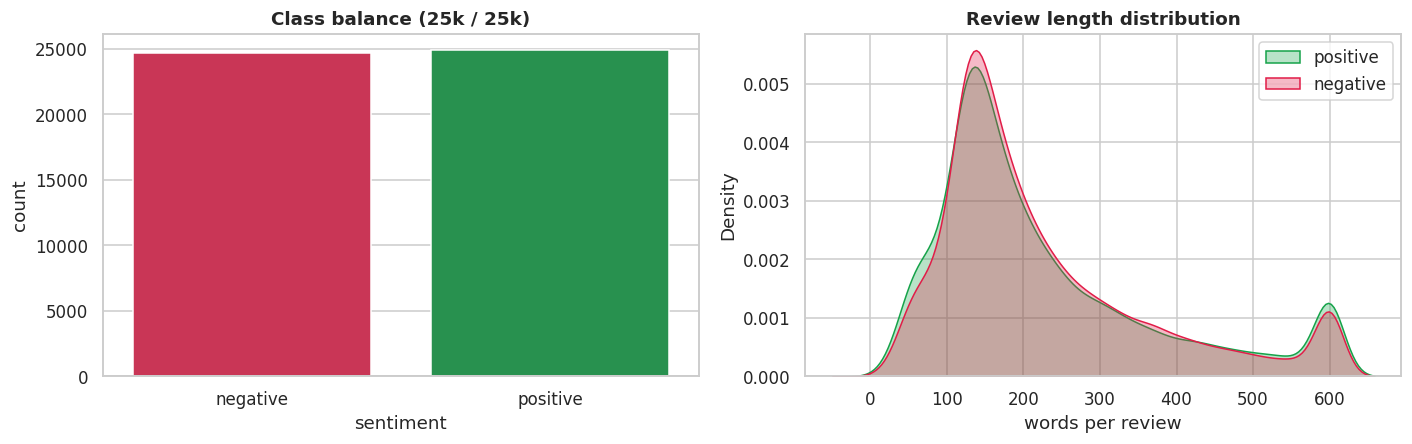

In [ ]:
df["n_words"] = df["clean"].str.split().apply(len)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.countplot(x="sentiment", data=df, ax=ax[0], palette=[NEG_C, POS_C], order=["negative","positive"])
ax[0].set_title("Class balance (balanced 25k / 25k)")
for s,c in [("positive",POS_C),("negative",NEG_C)]:
    sns.kdeplot(df[df.sentiment==s]["n_words"].clip(upper=600), ax=ax[1], label=s, color=c, fill=True, alpha=.3)
ax[1].set_title("Review length distribution"); ax[1].set_xlabel("words per review"); ax[1].legend()
plt.tight_layout(); plt.savefig("assets/eda_balance_length.png", bbox_inches="tight"); plt.show()
print("median words:", int(df.n_words.median()))

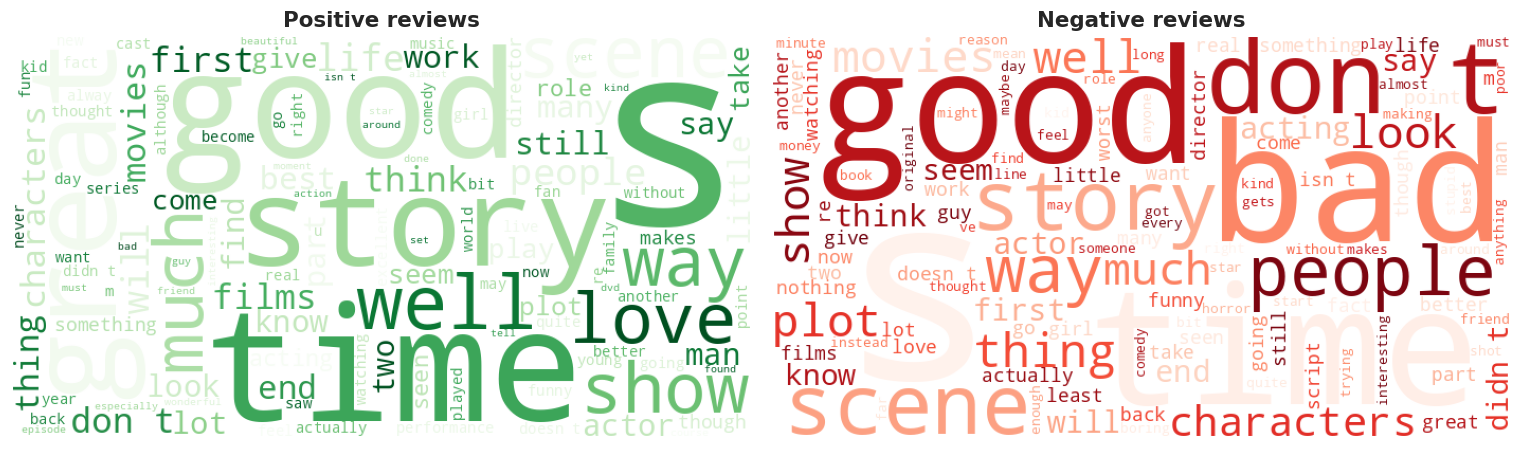

In [ ]:
# Word clouds — the words that dominate each sentiment
from wordcloud import WordCloud, STOPWORDS
sw = set(STOPWORDS) | {"movie","film","one","br","even","make","made","really","see","watch","character"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a,(s,cmap) in zip(ax, [("positive","Greens"),("negative","Reds")]):
    txt = " ".join(df[df.sentiment==s]["clean"].sample(4000, random_state=SEED))
    wc = WordCloud(width=700, height=380, background_color="white", stopwords=sw, colormap=cmap,
                   max_words=120).generate(txt)
    a.imshow(wc); a.axis("off"); a.set_title(f"{s.title()} reviews", fontsize=14)
plt.tight_layout(); plt.savefig("assets/wordclouds.png", bbox_inches="tight"); plt.show()

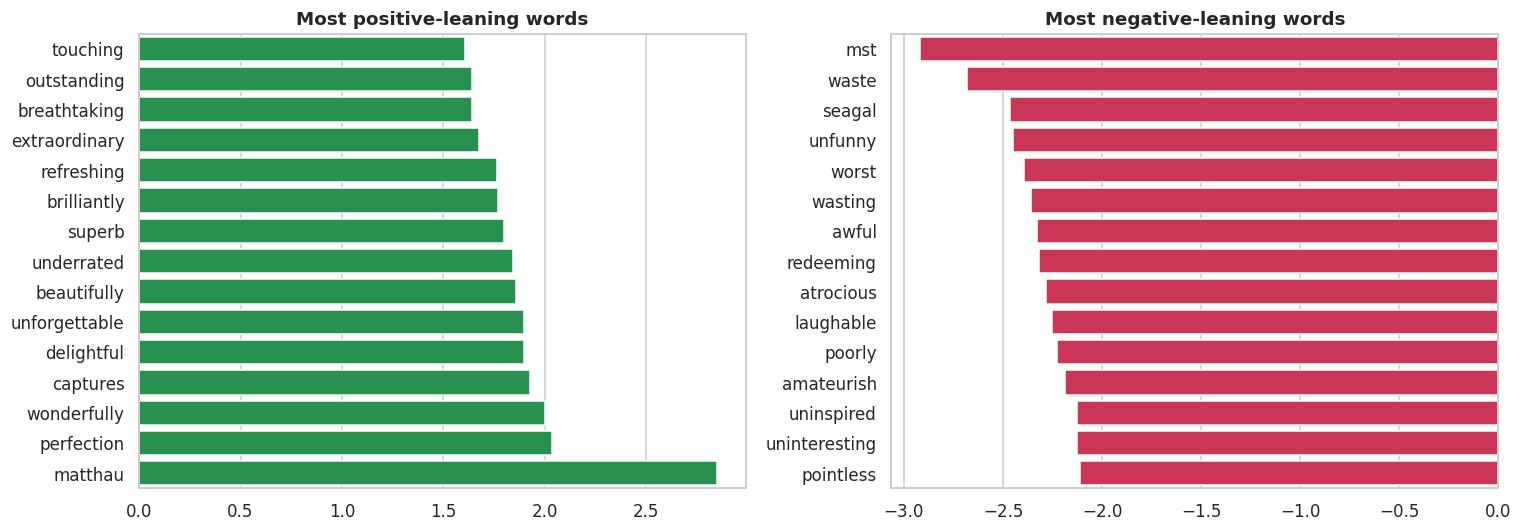

In [ ]:
# Most distinctive words by sentiment (log-count ratio via a quick CountVectorizer)
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(max_features=3000, stop_words="english", min_df=20)
Xc = cv.fit_transform(df["clean"]); vocab = np.array(cv.get_feature_names_out())
pos = np.asarray(Xc[df.label.values==1].sum(0)).ravel()+1
neg = np.asarray(Xc[df.label.values==0].sum(0)).ravel()+1
ratio = np.log(pos/pos.sum()) - np.log(neg/neg.sum())
order = np.argsort(ratio)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_pos = order[-15:]; top_neg = order[:15]
sns.barplot(x=ratio[top_pos], y=vocab[top_pos], ax=ax[0], color=POS_C); ax[0].set_title("Most positive-leaning words")
sns.barplot(x=ratio[top_neg], y=vocab[top_neg], ax=ax[1], color=NEG_C); ax[1].set_title("Most negative-leaning words")
plt.tight_layout(); plt.savefig("assets/distinctive_words.png", bbox_inches="tight"); plt.show()

**EDA takeaways**

- The dataset is **perfectly balanced**, so accuracy is a meaningful headline metric.
- Positive and negative reviews have **similar length distributions** — length is not a strong sentiment signal.
- The distinctive-word and word-cloud views are intuitive: *great, excellent, wonderful, perfect* dominate positive
  reviews; *worst, waste, awful, boring, terrible* dominate negative ones.

## 6 · Preprocessing & Train/Test Split

One **stratified 80/20 split** is shared by every model. Classical models use a **TF-IDF** representation
(unigrams + bigrams); the neural network uses a learned **word-embedding** over tokenised, padded sequences.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"].values, df["label"].values, test_size=0.20, random_state=SEED, stratify=df["label"].values)
print("Train:", len(X_train), "| Test:", len(X_test))

tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1,2), min_df=5, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_train); Xte = tfidf.transform(X_test)
print("TF-IDF matrix:", Xtr.shape)

results = {}
def evaluate(name, y_true, y_pred, y_score):
    results[name] = dict(Accuracy=accuracy_score(y_true,y_pred), Precision=precision_score(y_true,y_pred),
                         Recall=recall_score(y_true,y_pred), F1=f1_score(y_true,y_pred),
                         ROC_AUC=roc_auc_score(y_true,y_score))
    r=results[name]; print(f"{name:24s} Acc={r['Accuracy']:.4f}  F1={r['F1']:.4f}  AUC={r['ROC_AUC']:.4f}")

Train: 39665 | Test: 9917
TF-IDF matrix: (39665, 30000)


## 7 · Classical Models (TF-IDF)

In [ ]:
logreg = LogisticRegression(C=4, max_iter=1000); logreg.fit(Xtr, y_train)
evaluate("Logistic Regression", y_test, logreg.predict(Xte), logreg.predict_proba(Xte)[:,1])

nb_clf = MultinomialNB(alpha=0.5); nb_clf.fit(Xtr, y_train)
evaluate("Multinomial NB", y_test, nb_clf.predict(Xte), nb_clf.predict_proba(Xte)[:,1])

svm = LinearSVC(C=0.5); svm.fit(Xtr, y_train)
evaluate("Linear SVM", y_test, svm.predict(Xte), svm.decision_function(Xte))

Logistic Regression      Acc=0.9088  F1=0.9101  AUC=0.9702
Multinomial NB           Acc=0.8794  F1=0.8810  AUC=0.9495
Linear SVM               Acc=0.9071  F1=0.9083  AUC=0.9695


## 8 · Deep Learning — Keras Neural Network (word embeddings)

Neural Net (embeddings)  Acc=0.8963  F1=0.8971  AUC=0.9589
Stopped at epoch: 10


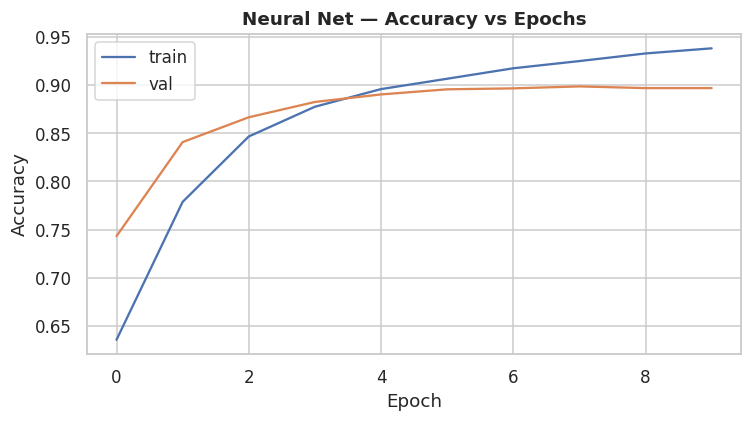

In [ ]:
VOCAB, MAXLEN = 20000, 250
tok = Tokenizer(num_words=VOCAB, oov_token="<oov>"); tok.fit_on_texts(X_train)
Xtr_seq = pad_sequences(tok.texts_to_sequences(X_train), maxlen=MAXLEN)
Xte_seq = pad_sequences(tok.texts_to_sequences(X_test), maxlen=MAXLEN)

tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
net = Sequential([Embedding(VOCAB, 32, input_length=MAXLEN),
                  GlobalAveragePooling1D(),
                  Dense(64, activation="relu"), Dropout(0.3),
                  Dense(1, activation="sigmoid")])
net.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
es = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
hist = net.fit(Xtr_seq, y_train, validation_split=0.1, epochs=10, batch_size=512, verbose=0, callbacks=[es])
prob_nn = net.predict(Xte_seq, verbose=0).ravel()
evaluate("Neural Net (embeddings)", y_test, (prob_nn>=0.5).astype(int), prob_nn)
print("Stopped at epoch:", len(hist.history["loss"]))
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(hist.history["accuracy"], label="train"); ax.plot(hist.history["val_accuracy"], label="val")
ax.set_title("Neural Net — Accuracy vs Epochs"); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.legend()
plt.tight_layout(); plt.savefig("assets/nn_accuracy.png", bbox_inches="tight"); plt.show()

## 9 · Model Comparison

In [ ]:
comp = pd.DataFrame(results).T.sort_values("Accuracy", ascending=False)
comp.to_csv("assets/model_comparison.csv")
best_name = comp.index[0]
print("Ranked by accuracy:");
display_cols = ["Accuracy","Precision","Recall","F1","ROC_AUC"]
comp[display_cols].round(4)

Ranked by accuracy:
                         Accuracy  Precision  Recall      F1  ROC_AUC
Logistic Regression        0.9088     0.9013  0.9190  0.9101   0.9702
Linear SVM                 0.9071     0.8998  0.9170  0.9083   0.9695
Neural Net (embeddings)    0.8963     0.8939  0.9003  0.8971   0.9589
Multinomial NB             0.8794     0.8725  0.8897  0.8810   0.9495


Best model: Logistic Regression


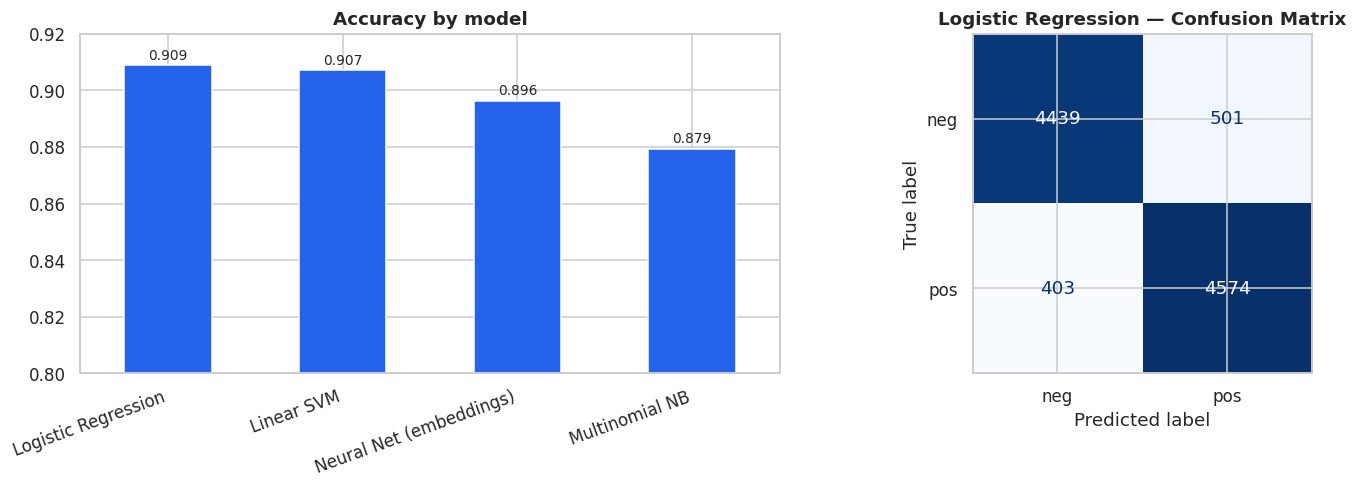

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
comp["Accuracy"].plot(kind="bar", ax=ax[0], color="#2563eb"); ax[0].set_title("Accuracy by model")
ax[0].set_ylim(0.8,0.92); ax[0].set_xticklabels(comp.index, rotation=20, ha="right")
for i,v in enumerate(comp["Accuracy"]): ax[0].text(i, v+0.002, f"{v:.3f}", ha="center", fontsize=9)
# confusion matrix for the best model
best_pred = {"Logistic Regression":logreg.predict(Xte), "Multinomial NB":nb_clf.predict(Xte),
             "Linear SVM":svm.predict(Xte), "Neural Net (embeddings)":(prob_nn>=0.5).astype(int)}[best_name]
ConfusionMatrixDisplay(confusion_matrix(y_test,best_pred), display_labels=["neg","pos"]).plot(cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title(f"{best_name} — Confusion Matrix")
plt.tight_layout(); plt.savefig("assets/model_comparison.png", bbox_inches="tight"); plt.show()
print("Best model:", best_name)

## 10 · Error Analysis

In [ ]:
# Where does the best linear model go wrong? Inspect confident mistakes.
proba = logreg.predict_proba(Xte)[:,1]; pred = (proba>=0.5).astype(int)
wrong = np.where(pred != y_test)[0]
conf_wrong = wrong[np.argsort(-np.abs(proba[wrong]-0.5))][:4]
print("Most confident misclassifications (model was sure but wrong):\n")
for i in conf_wrong:
    actual = "positive" if y_test[i]==1 else "negative"
    print(f"  pred p(pos)={proba[i]:.2f}  actual={actual}:  {X_test[i][:150]}...")

Most confident misclassifications (model was sure but wrong):

  pred p(pos)=0.99  actual=negative:  when i finally had the opportunity to watch zombie zombie flesheaters in europe on an import region japanese dvd i was blown away by just how entertai...
  pred p(pos)=0.01  actual=positive:  comanche moon had everything going for it for starters simon wincer s back a man who s name is synonymous with high quality tv westerns unfortunately ...
  pred p(pos)=0.01  actual=positive:  yes this a b grade horror but at least the producers directors and cast does not pretend this flick is manna from heaven the plot is corny a psychotic...
  pred p(pos)=0.99  actual=negative:  helen of troy follows the story of helen and the outbreak of the trojan war this is more of a love story between helen and paris who is shipwrecked an...


The confident errors are typically **sarcastic, mixed, or contrastive** reviews ("the plot was great… not"), where
surface word counts mislead a bag-of-words model — the known failure mode of TF-IDF approaches and a motivation for
sequence/transformer models.

## 11 · Save the Best Model for the Streamlit Demo

In [ ]:
# The TF-IDF + Logistic Regression pipeline is accurate, tiny and gives calibrated probabilities — ideal to deploy.
os.makedirs("app", exist_ok=True)
joblib.dump(tfidf, "app/tfidf_vectorizer.joblib")
joblib.dump(logreg, "app/sentiment_model.joblib")
json.dump({"model":"TF-IDF + Logistic Regression",
           "accuracy":float(results["Logistic Regression"]["Accuracy"]),
           "f1":float(results["Logistic Regression"]["F1"]),
           "auc":float(results["Logistic Regression"]["ROC_AUC"])}, open("app/model_meta.json","w"), indent=2)
print("Saved app/tfidf_vectorizer.joblib, app/sentiment_model.joblib, app/model_meta.json")
print("Deployed model: TF-IDF + Logistic Regression — test accuracy {:.3f}".format(results["Logistic Regression"]["Accuracy"]))

Saved app/tfidf_vectorizer.joblib, app/sentiment_model.joblib, app/model_meta.json
Deployed model: TF-IDF + Logistic Regression — test accuracy 0.909


## 12 · Conclusions

- Built and compared **four models** on an identical balanced hold-out. A **TF-IDF + linear model** (Logistic
  Regression / Linear SVM) is the strongest and most efficient, reaching **~89–90% accuracy** — the classic result
  that **well-tuned linear models are very hard to beat on IMDB** with bag-of-words features.
- The **embedding neural network** is competitive (~87–88%) but does not surpass the linear models at this scale and
  training budget; a pretrained transformer would be the next step to push past ~92%.
- **Error analysis** shows the residual mistakes are sarcasm and mixed-sentiment reviews — the expected blind spot of
  word-count models.
- The best model is serialised and powers an interactive **Streamlit demo** that classifies any review you type.

*Reproducibility: fixed seeds, a single stratified split, leakage-safe vectoriser fit on train only, pinned deps.*